# Computing interval multiplicities and splittings

A finite encoding retains spaces and maps, so we can ask whether a proposed piece actually splits off. We will construct a square module, recover its interval multiplicities, and request maps that reconstruct it. Then a branching example will show what a non-interval residual means.

You need TamerOp and CairoMakie, and familiarity with matrices and [finite modules](../spaces_and_maps.md). The [mathematical lesson](../decomposition.md) explains summands; the [API reference](../src/reference/decomposition.md) gives the exact contracts. All algebra here is rational on the declared finite poset. Direct diagrams are legitimate inputs; a point cloud is not required.


In [1]:
import TamerOp as OP
using CairoMakie
A = OP.Advanced
QQ = Rational{BigInt}
field = OP.CoreModules.QQField();


TamerOp.CoreModules.CoeffFields.QQField()

## Start with pieces we can recognize

The square has vertices 1 (bottom), 2 and 3 (middle), and 4 (top). Its module is a sum of the full square, the upper edge `{2,4}`, and two copies supported only at 4. The coordinates below name those copies, so the expected multiplicities are known before we run a decomposition. In an independently supplied module the coordinates need not reveal them.


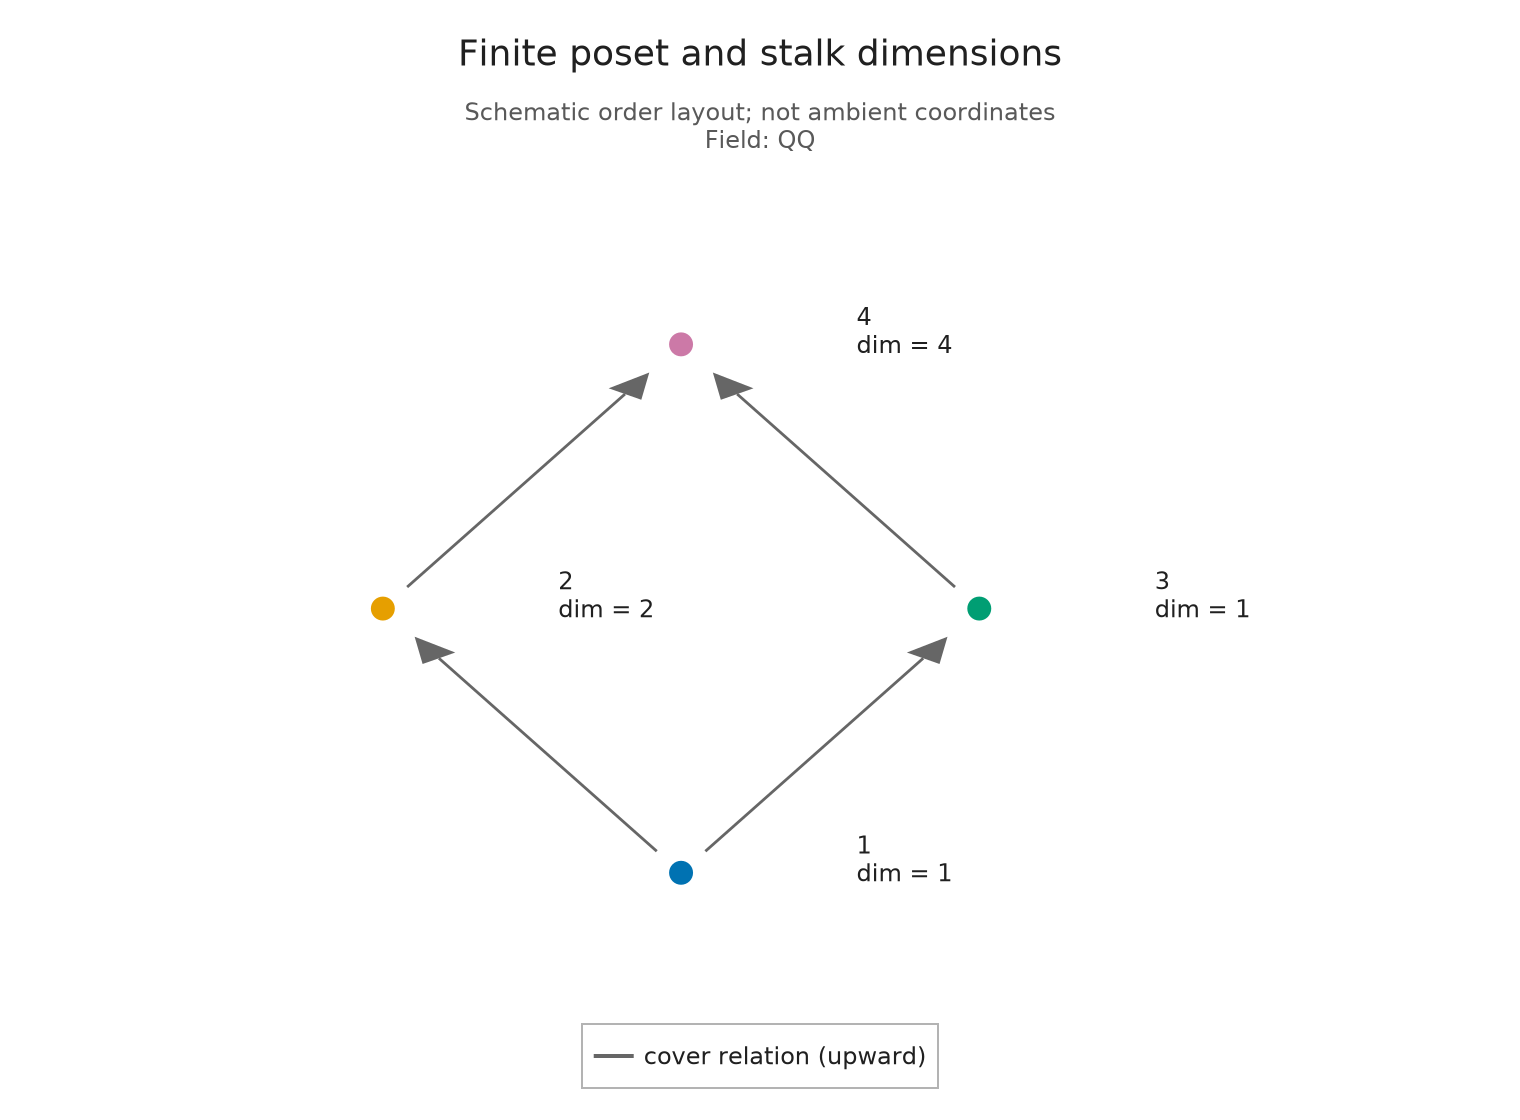

In [2]:
P = A.ProductOfChainsPoset((2, 2))
supports = [[1, 2, 3, 4], [2, 4], [4], [4]]
active = [findall(I -> v in I, supports) for v in 1:4]
maps = Dict((u, v) => QQ[i == j for i in active[v], j in active[u]]
            for (u, v) in A.cover_edges(P))
M = A.PModule{QQ}(P, length.(active), maps; field)
@assert OP.dimensions(M).stalks == [1, 2, 1, 4]
OP.visualize(M)


## Ask for one multiplicity

The first call asks how many sink-only intervals split off the **whole** module. The generalized-rank call instead looks only at the sink stalk. Its answer includes the two other summands that also reach vertex 4.


In [3]:
multiplicity = OP.interval_multiplicity(M; vertices=[4])
restricted_rank = OP.generalized_rank(M; vertices=[4])
@assert multiplicity == 2
@assert restricted_rank == 4
(; multiplicity, restricted_rank)


(multiplicity = 2, restricted_rank = 4)

## Choose the scope of the search

A chosen family gives exact answers for those supports. Its residual may contain unqueried intervals: `missing` means that the global decomposability question is still undecided. A complete search first prunes impossible supports with top/socle endpoint data. The default result retains counts and residual dimensions.


In [4]:
selected = OP.interval_decomposition(M; family=[[4]])
@assert ismissing(OP.is_interval_decomposable(selected))
@assert A.residual_dimensions(selected) == [1, 2, 1, 2]
whole = OP.interval_decomposition(M)
@assert A.interval_family(whole) == [[1, 2, 3, 4], [2, 4], [4]]
@assert A.interval_multiplicities(whole) == [1, 1, 2]
@assert OP.is_interval_decomposable(whole) === true
OP.describe(whole)


(kind = :interval_decomposition, category = :finite_poset_representations, field = TamerOp.CoreModules.CoeffFields.QQField(), vertices = 4, interval_types = 3, interval_copies = 4, residual_dimension = 0, exhaustive = true, interval_decomposable = true, witnesses = false, search = (scanned = 3, candidates = 3, tested = 3))

## Recover a splitting in the supplied coordinates

Request witnesses when we need actual modules and maps. For the selected sink-only interval, `inclusion` inserts its two copies and `projection` extracts them. The other two intervals form the residual. The displayed matrix at vertex 4 is the computed projection; its source and target dimensions are 4 and 2.


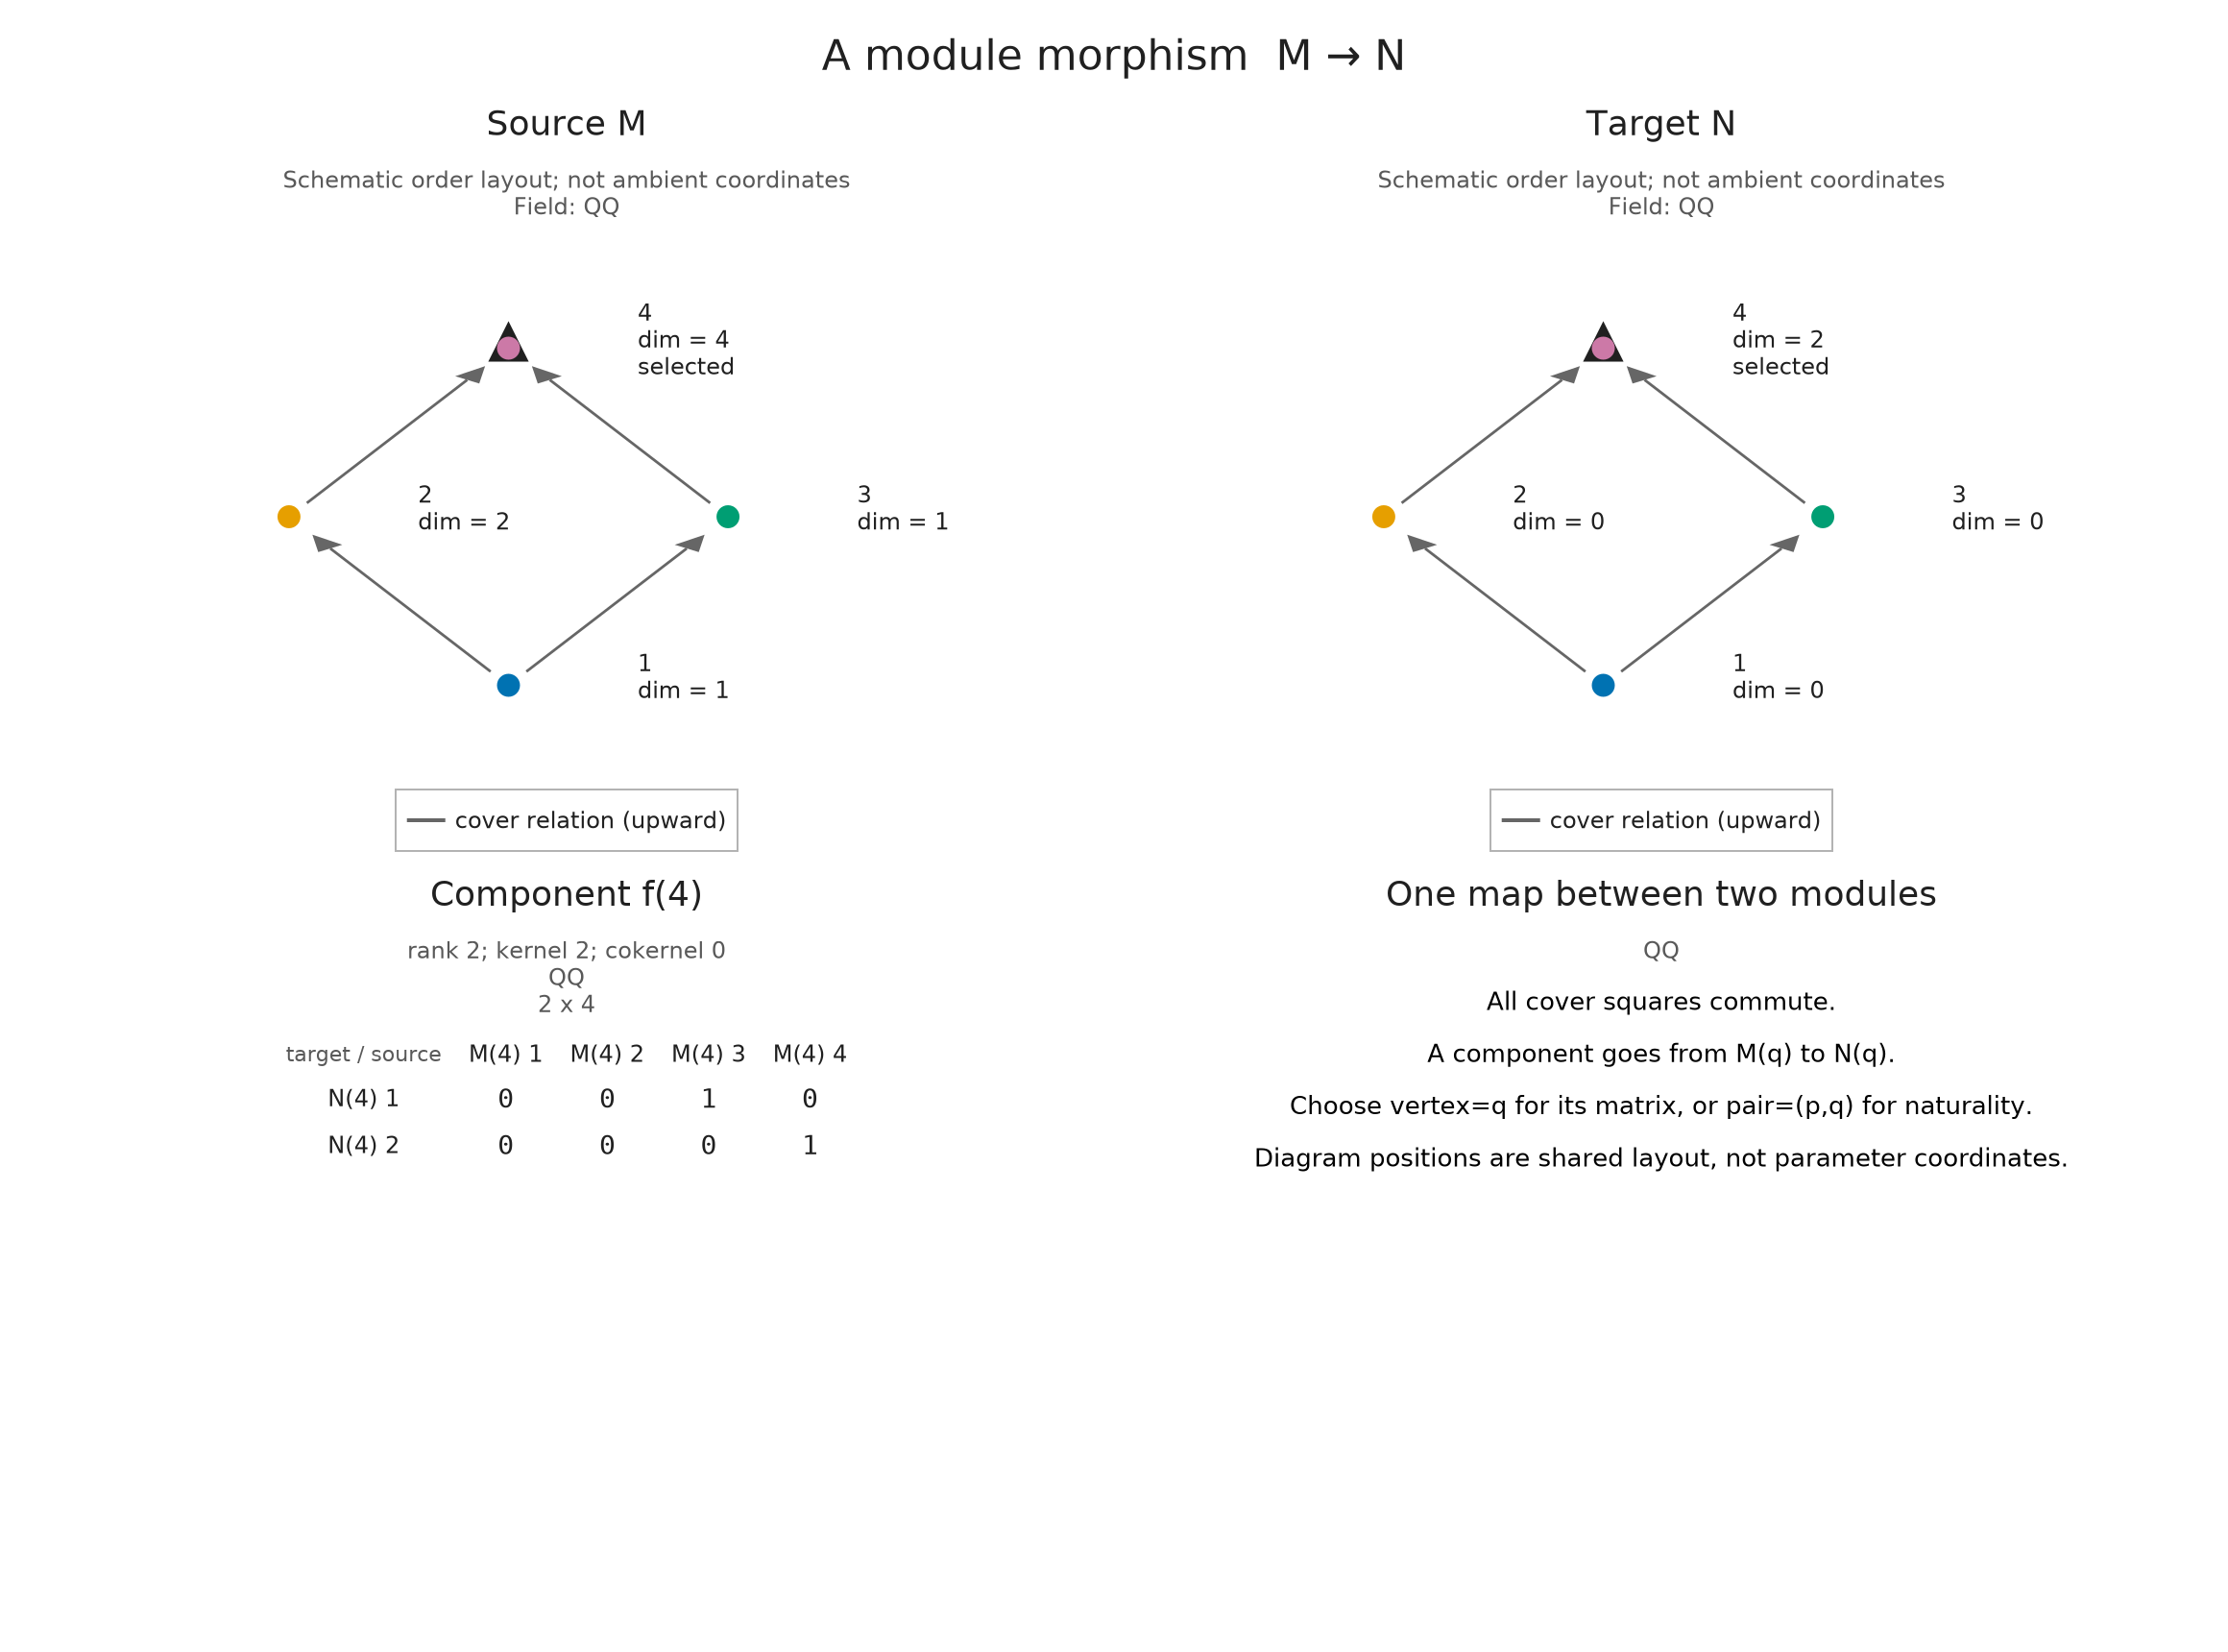

In [5]:
split = OP.interval_decomposition(M; family=[[4]], witnesses=true)
w = A.decomposition_maps(split)
@assert A.check_interval_decomposition(split; throw=true).splitting_checked
@assert OP.dimensions(w.summand).stalks == [0, 0, 0, 2]
@assert OP.dimensions(w.residual).stalks == [1, 2, 1, 2]
OP.visualize(w.projection; vertex=4)


The reconstruction identity is stronger than matching dimensions. At every vertex, the interval and residual idempotents add to the identity. The validator also checks naturality on every cover, both retractions and the mixed zero composites.


In [6]:
using LinearAlgebra
for v in 1:4
    i = A.component(w.inclusion, v)
    p = A.component(w.projection, v)
    j = A.component(w.residual_inclusion, v)
    q = A.component(w.residual_projection, v)
    @assert i * p + j * q == Matrix{QQ}(LinearAlgebra.I, OP.dimensions(M, v).stalk, OP.dimensions(M, v).stalk)
end
OP.describe(split)


(kind = :interval_decomposition, category = :finite_poset_representations, field = TamerOp.CoreModules.CoeffFields.QQField(), vertices = 4, interval_types = 1, interval_copies = 2, residual_dimension = 6, exhaustive = false, interval_decomposable = missing, witnesses = true, search = (scanned = 1, candidates = 1, tested = 1))

## See a residual that contains no intervals

Three incomparable sources map into a two-dimensional sink along three distinct lines. No interval copy admits a retraction. A complete search therefore returns `false`, and the residual is the entire module. This is an algebraic statement about these maps; a nonempty support picture alone could not establish it.


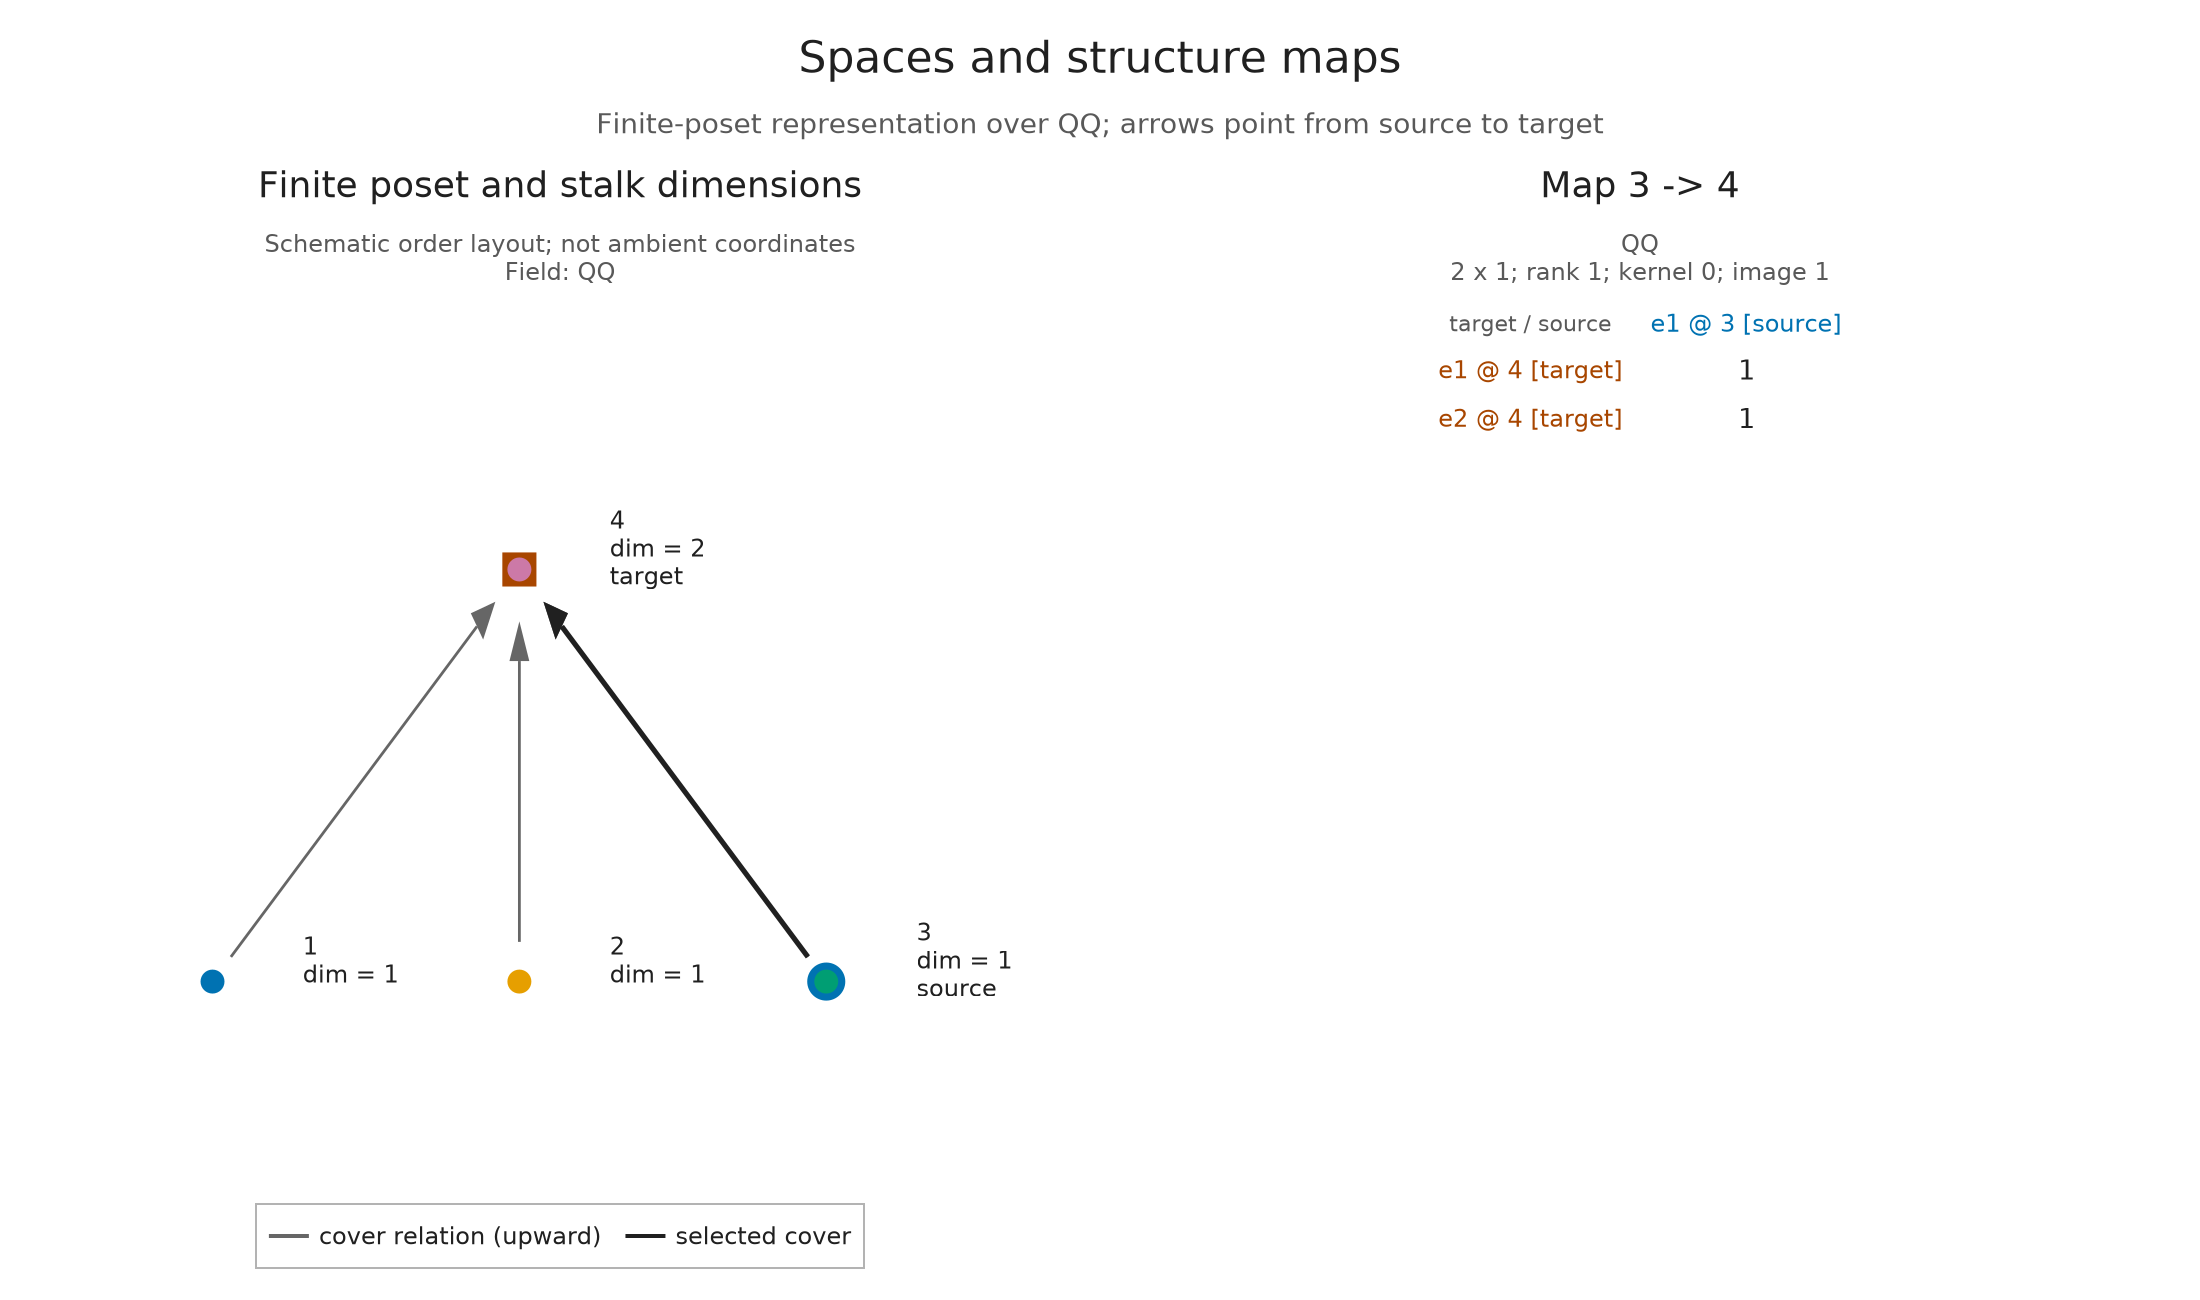

In [7]:
star = A.FinitePoset(Bool[1 0 0 1; 0 1 0 1; 0 0 1 1; 0 0 0 1])
three_lines = A.PModule{QQ}(star, [1, 1, 1, 2],
    Dict((1, 4) => reshape(QQ[1, 0], 2, 1),
         (2, 4) => reshape(QQ[0, 1], 2, 1),
         (3, 4) => reshape(QQ[1, 1], 2, 1)); field)
remainder = OP.interval_decomposition(three_lines; witnesses=true)
@assert OP.is_interval_decomposable(remainder) === false
@assert isempty(A.interval_multiplicities(remainder))
@assert A.residual_dimensions(remainder) == [1, 1, 1, 2]
OP.visualize(A.decomposition_maps(remainder).residual; kind=:module_inspector, pair=(3, 4))


## Use the same algebra after encoding

An `EncodingResult` also carries a classifier from original parameters into the finite base. For this grid, the interval labels still refer to finite vertices. The returned provenance records that category; it does not declare that the interval list is complete in a different ambient category. Filtered-data encodings can enter through the same calls.


In [8]:
classifier = A.GridEncodingMap(P, ([0, 1], [0, 1]))
encoded = OP.EncodingResult(P, M, classifier)
cache = OP.SessionCache()
@assert OP.interval_multiplicity(encoded; vertices=[4], cache) == 2
encoded_result = OP.interval_decomposition(encoded; cache)
@assert OP.is_interval_decomposable(encoded_result) === true
OP.provenance(encoded_result)


(category = :finite_poset_representations, base_poset = ProductOfChainsPoset(axes=(2, 2), orientation=(1, 1), nvertices=4), field = TamerOp.CoreModules.CoeffFields.QQField(), model = :hom_composition_pairing, candidate_pruning = :top_socle_degree_zero, exhaustive = true, ambient_identification = :not_asserted)

## Put the pieces beside the whole module

We can now use the splitting to read a picture of the module. Ask for all interval witnesses, then give the result to `summand_session`. The first row compares the full module, the selected blocks, and their complement. Below it, each block has its own view. The two copies supported at vertex 4 occupy one block with multiplicity 2; they have not been collapsed into a single one-dimensional space.

Without a classifier, the node positions show the order of the finite poset. Keeping those positions fixed lets us compare the same vertex across panels. Labels give the actual dimensions, and the selected inclusion and projection use the coordinates supplied to the computation.


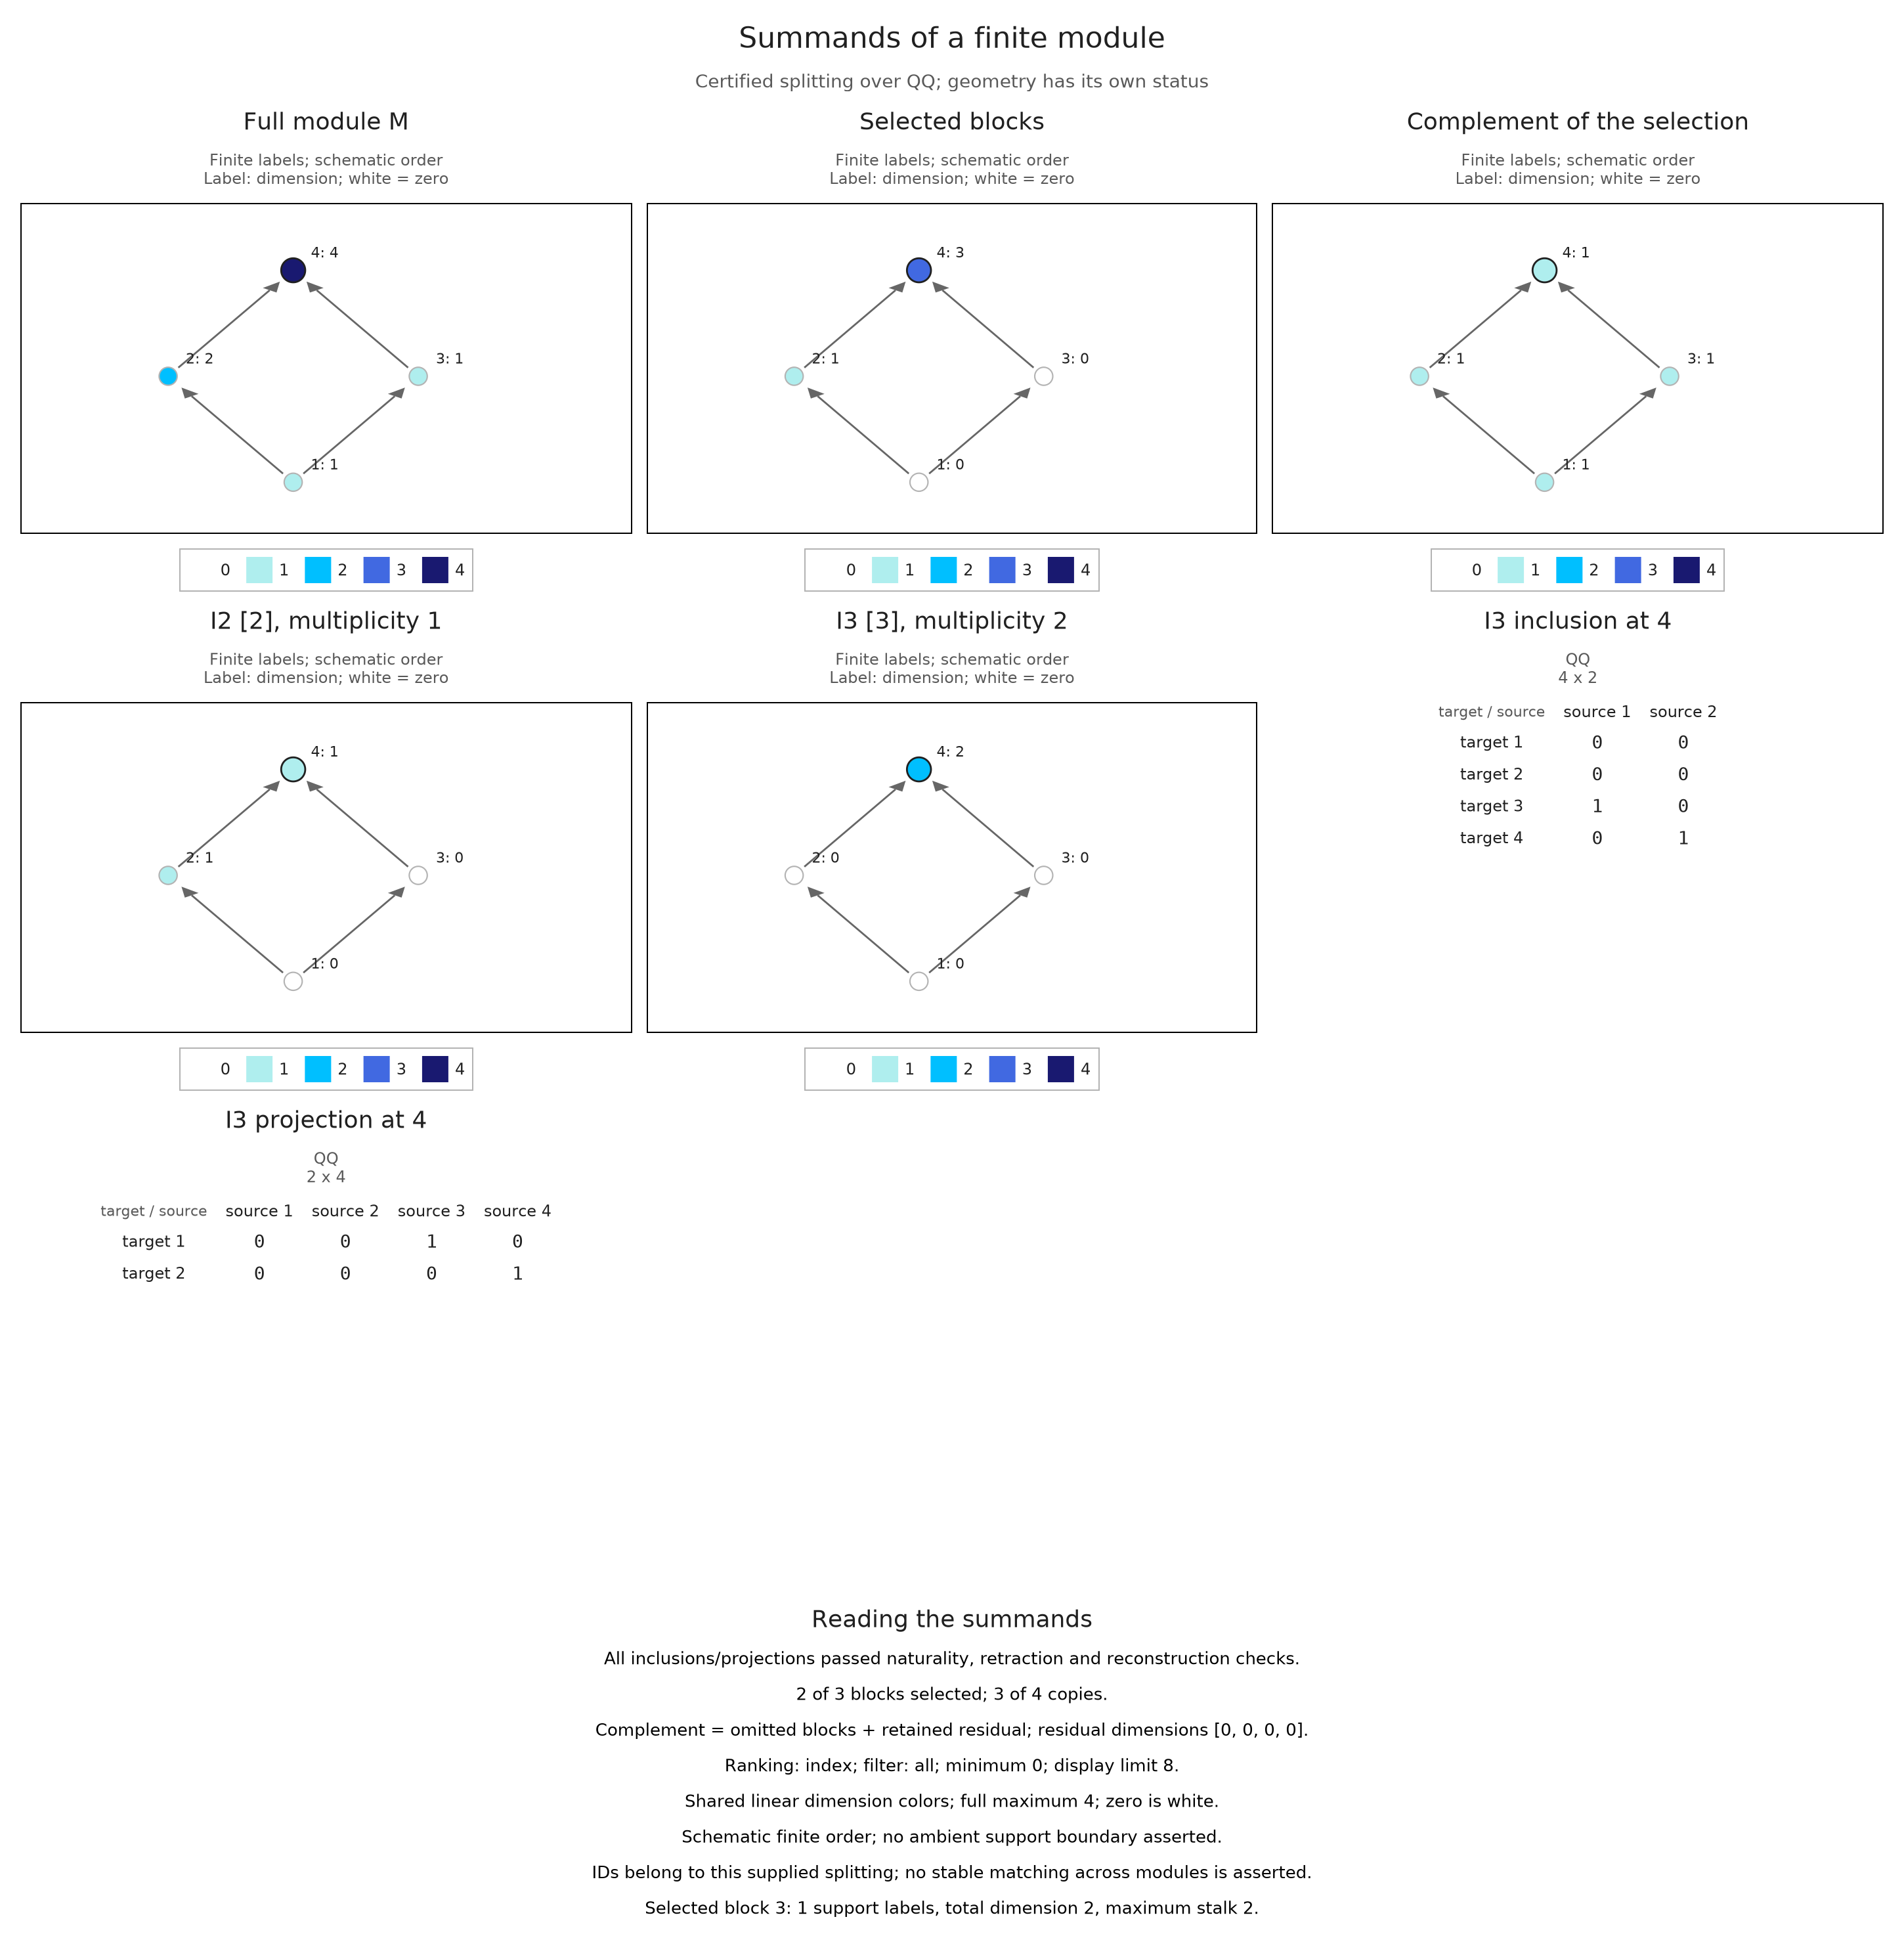

In [9]:
complete = OP.interval_decomposition(M; witnesses=true)
collection = OP.summand_collection(complete)
viewer = OP.summand_session(collection; selected=[2, 3], focus=3, vertex=4)
view = A.inspection_snapshot(viewer)
@assert view.metadata.selected_dimensions == [0, 1, 0, 3]
@assert view.metadata.complement_dimensions == [1, 1, 1, 1]
OP.visualize(view)


## Recover supports in the parameter plane

The classifier tells us which finite label to use at an original parameter. Here we place the square at the nonuniform coordinates `[-3, 2]` and `[1, 5]`. Each grid cell extends to the next threshold, including its lower edge and excluding its upper edge; the last cells continue beyond the drawing window. Thus the top-right block fills `x ≥ 2, y ≥ 5`, clipped by our chosen box.

These boundaries come from the classifier. Solid edges are included, dashed edges excluded, and dotted edges mark the viewing window. They describe the drawn region independently of the algebraic fact that the piece splits off. A gray region has no finite label; a white region has a represented zero-dimensional stalk.


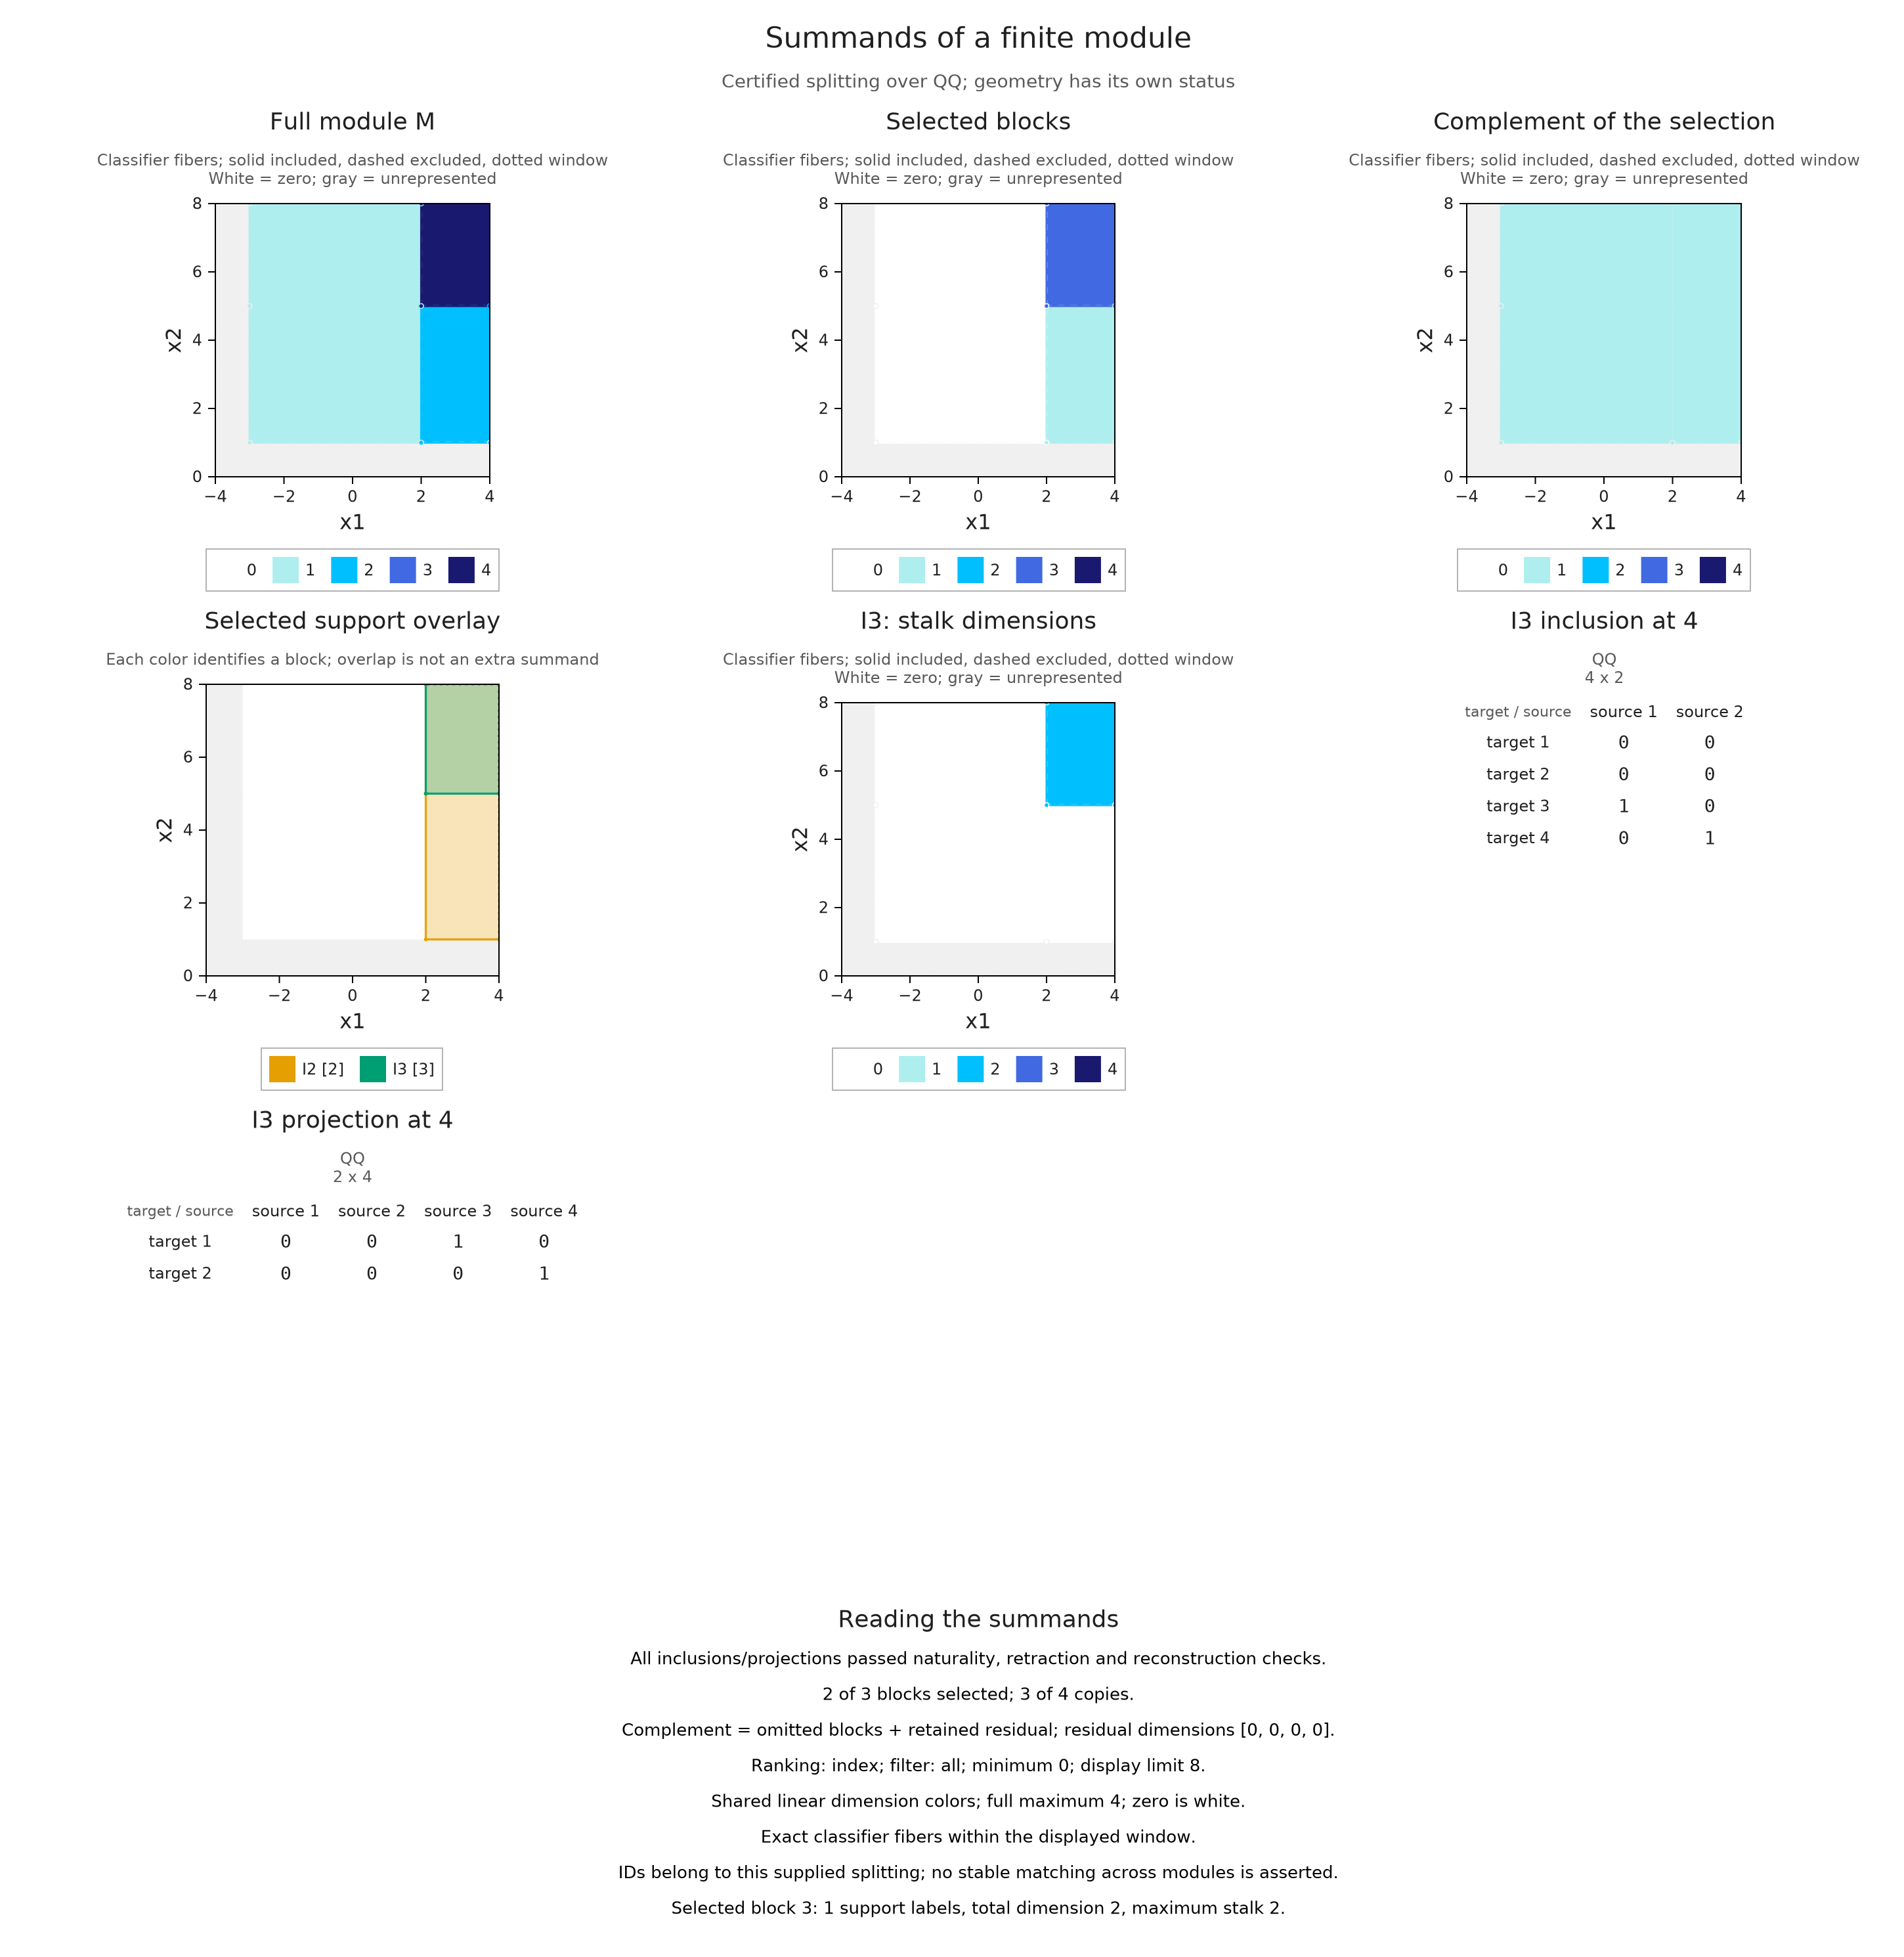

In [10]:
support_encoding = OP.EncodingResult(P, M,
    A.GridEncodingMap(P, ([-3, 2], [1, 5])))
support_viewer = OP.summand_session(collection; encoding=support_encoding,
    box=([-4, 0], [4, 8]), selected=[2, 3], focus=3, vertex=4,
    layout=:overlay)
OP.visualize(A.inspection_snapshot(support_viewer))


## Choose which blocks to compare

There are several useful ways to order a gallery. A multiplicity counts copies of an interval; a support count counts finite labels; a total dimension adds stalk dimensions over those labels. None of these is an ambient area. Choose the statistic that answers your question, and keep the complement in view when a limit or filter hides blocks.

Sorting changes the display order while the original IDs remain fixed. In this example the largest multiplicity belongs to block 3, so retaining one block leaves dimensions `(1,2,1,2)` in the complement. The logarithmic color scale still draws zero separately. Shared scales use the full module's range even as the selection changes.


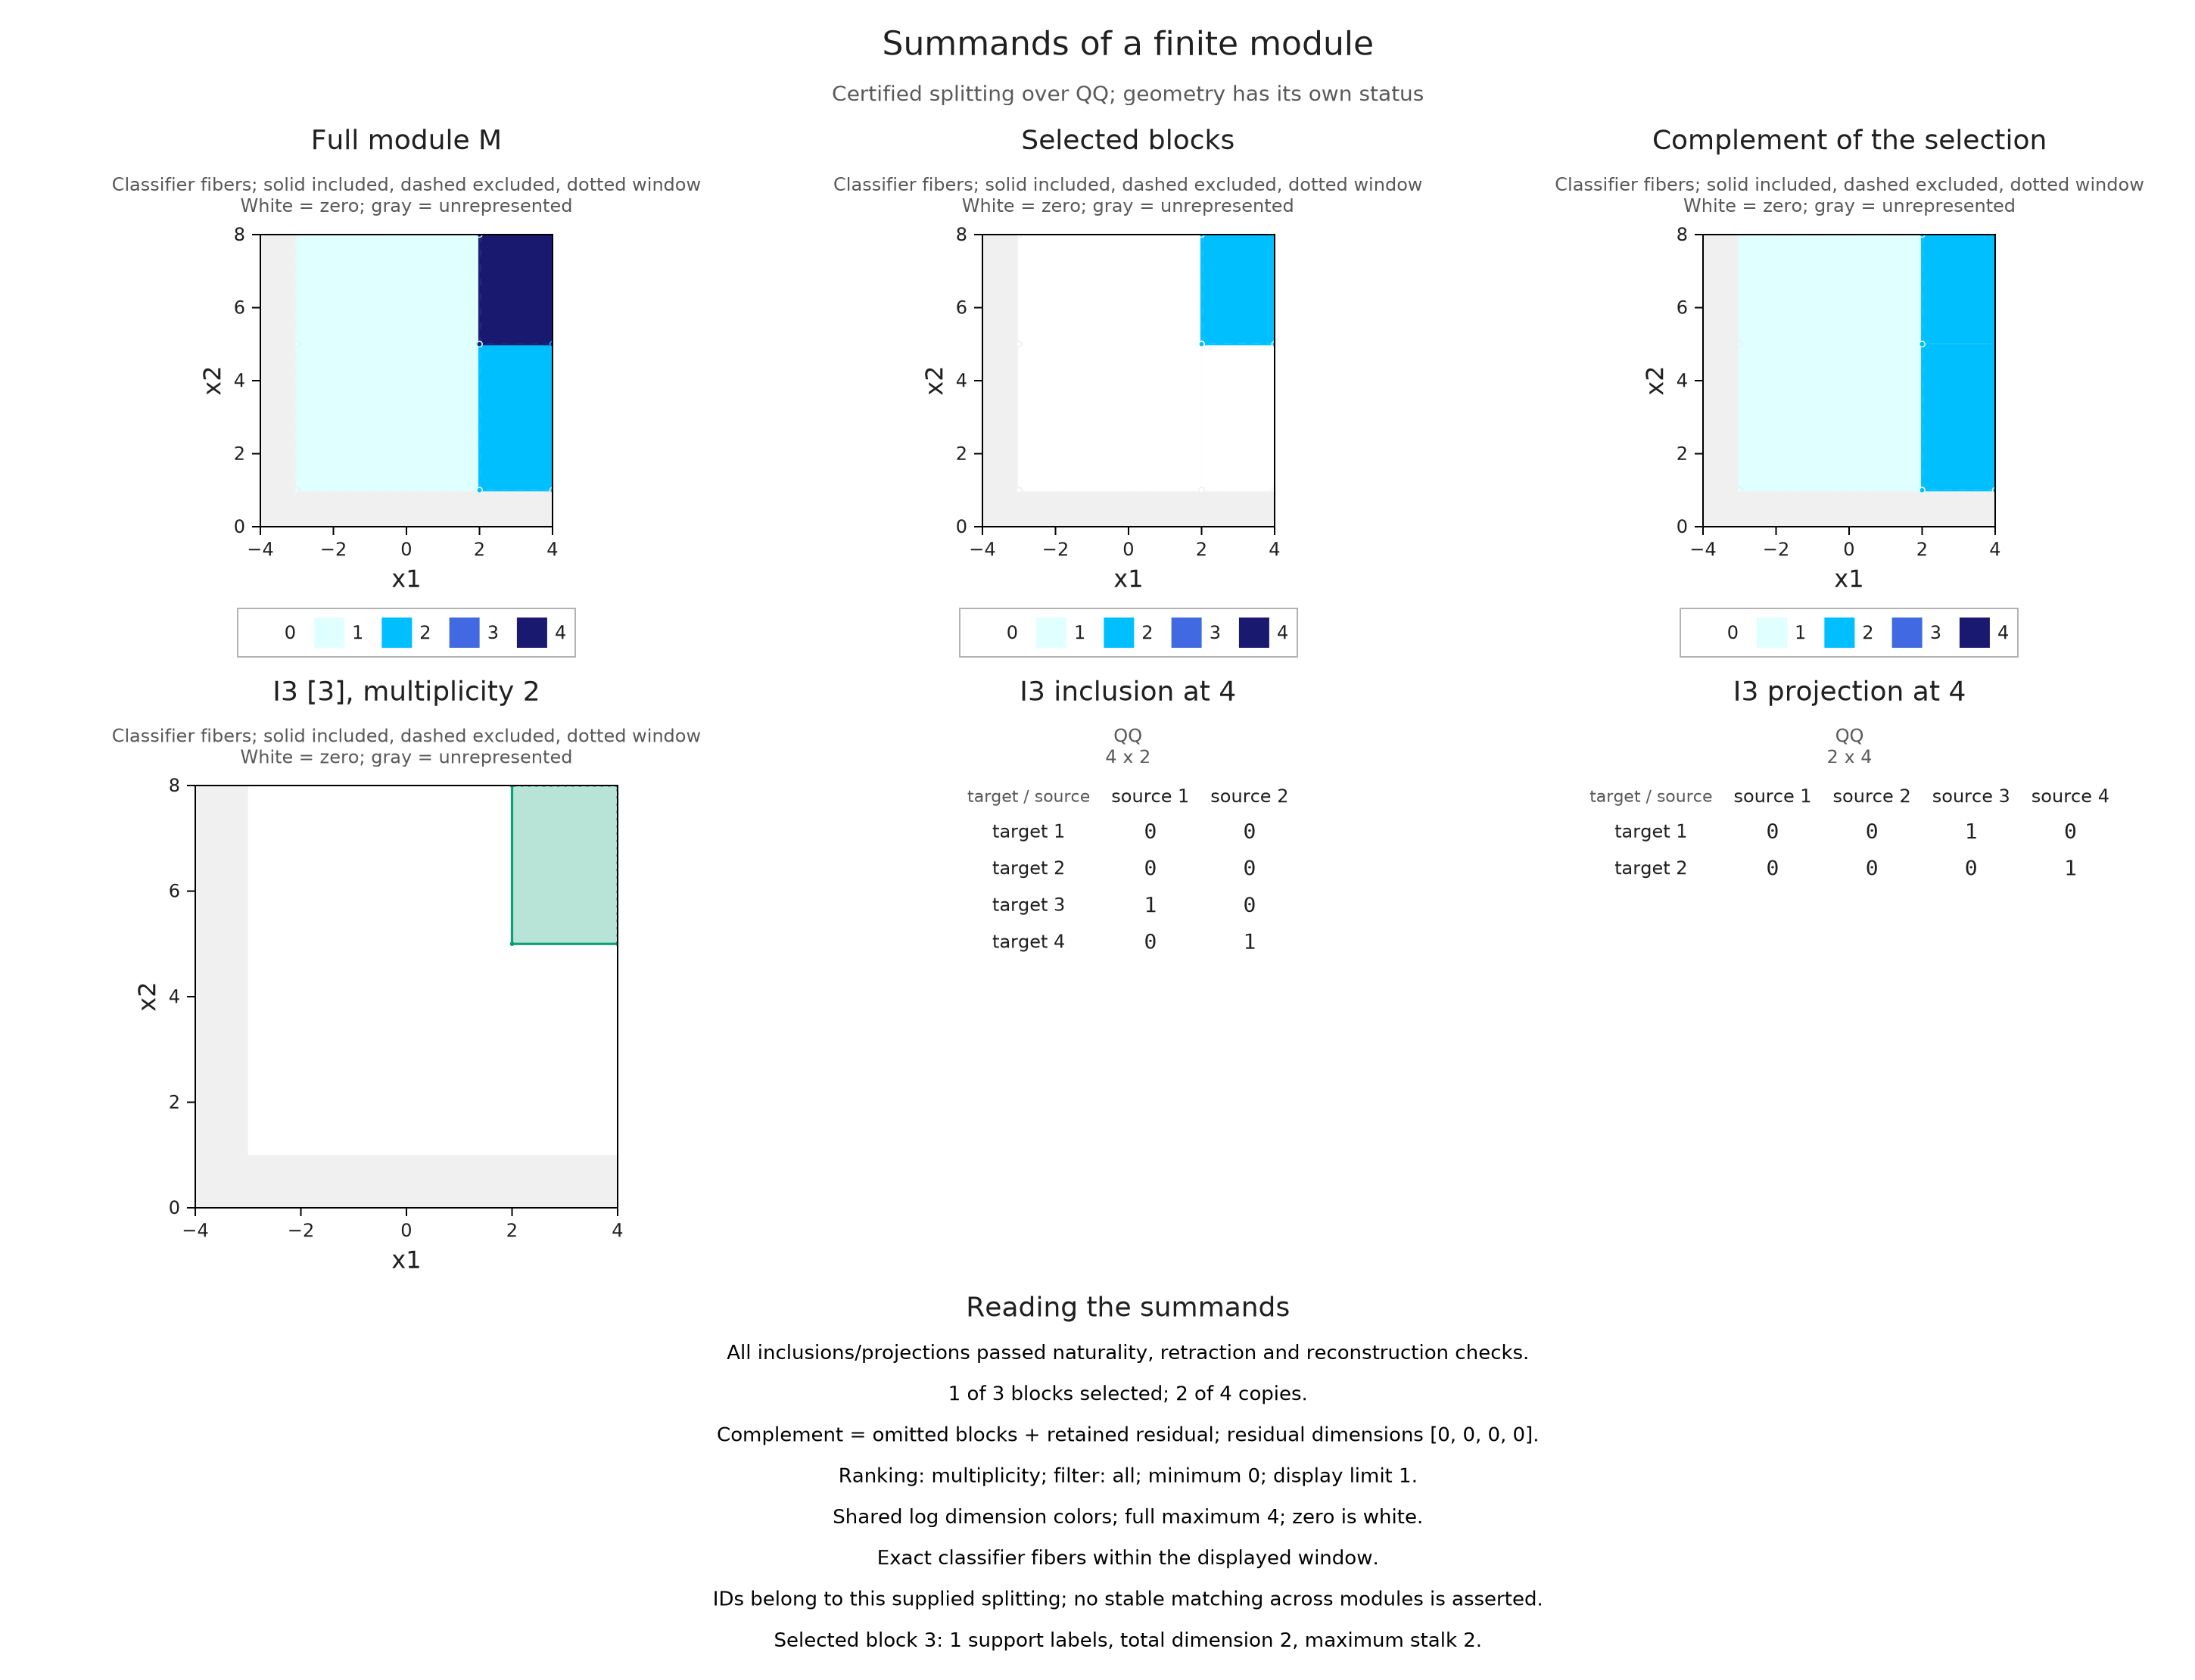

In [11]:
A.select_inspection!(support_viewer; selected=nothing,
    sort_by=:multiplicity, limit=1, layout=:isolate, scale=:log)
@assert A.inspection_selection(support_viewer).ids == [3]
@assert A.inspection_snapshot(support_viewer).metadata.complement_dimensions == [1, 2, 1, 2]
OP.visualize(A.inspection_snapshot(support_viewer))


## Look at maps between the pieces

Two summands can admit maps between them even when their chosen embeddings in the direct sum have zero cross projections. For the square example, a map from the sink-supported block into the constant square is free to choose a row at the sink. A map in the other direction must commute with the incoming arrows, which forces that component to be zero.

The Hom table counts all module morphisms between the displayed blocks, with sources in columns and targets in rows. Selecting an entry shows a basis morphism in the stored coordinates. This is an ordinary Hom space, not adjacency in the finite poset and not an evaluation quotient such as Hom^alpha. These extra computations are opt-in and bounded separately from drawing the gallery.


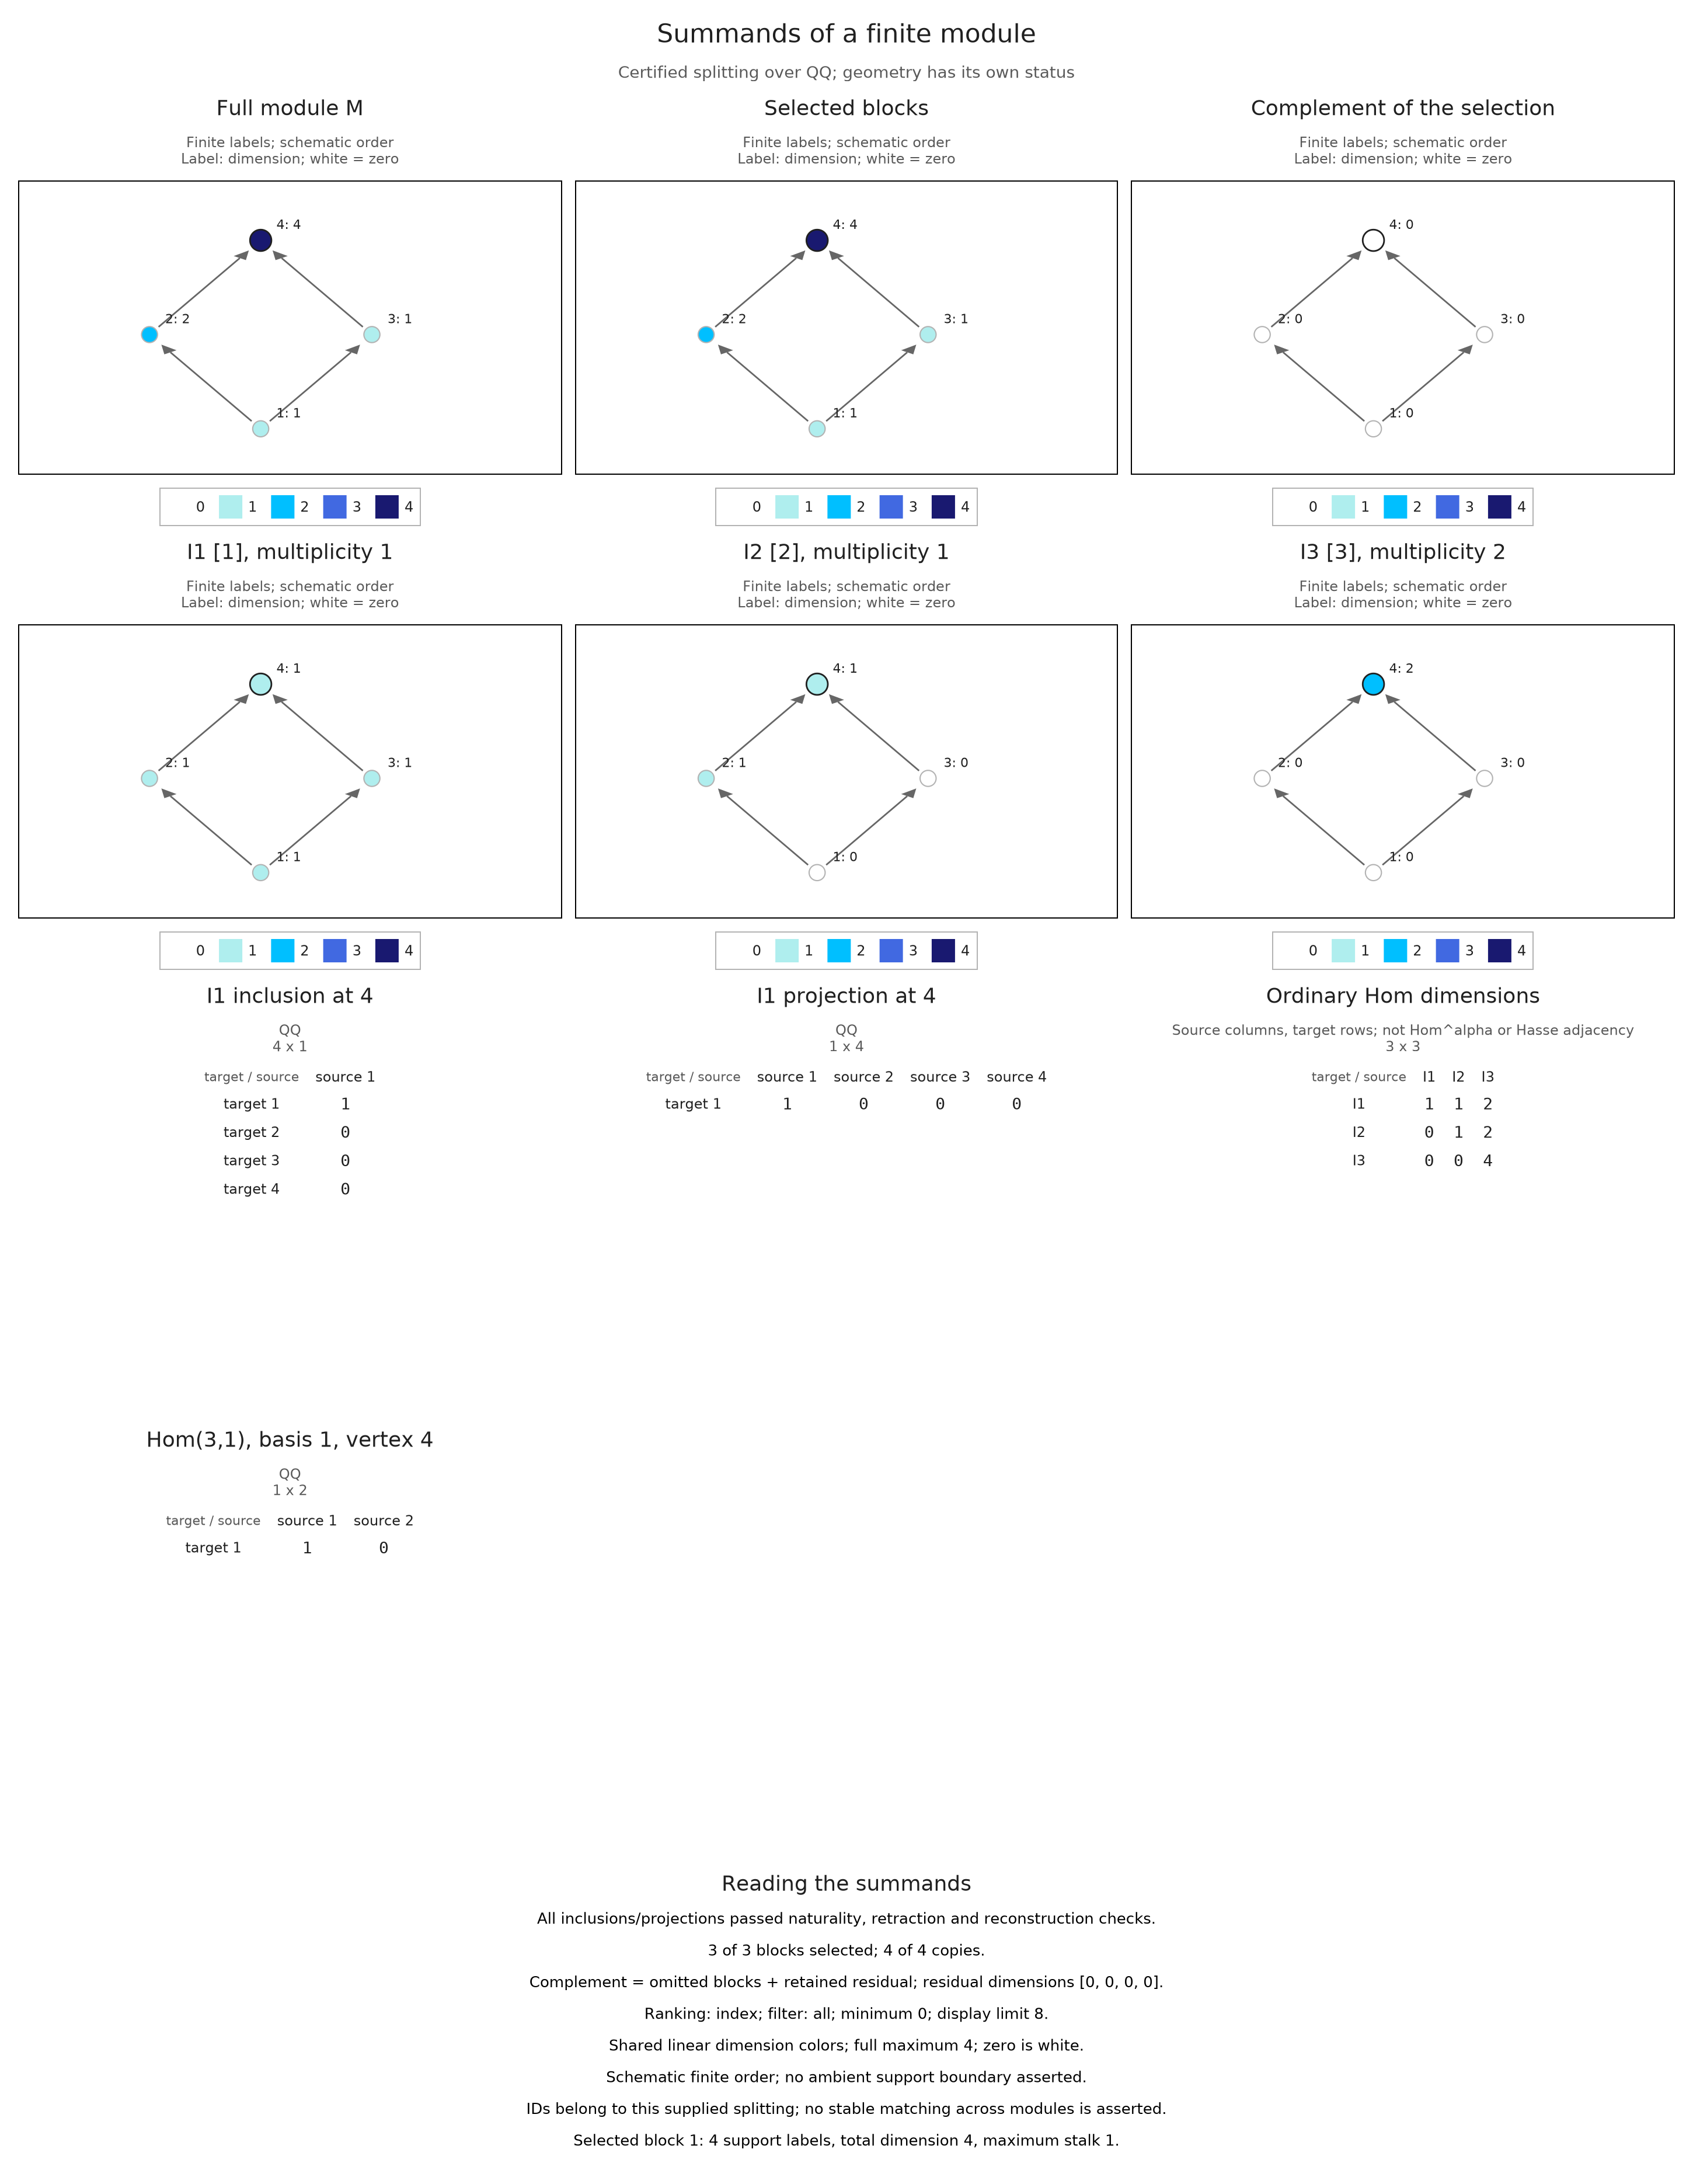

In [12]:
A.select_inspection!(viewer; selected=nothing, hom=true,
    hom_pair=(3, 1), vertex=4)
hom_view = A.inspection_snapshot(viewer)
@assert hom_view.metadata.hom_dimensions == [1 1 2; 0 1 2; 0 0 4]
@assert size(hom_view.metadata.hom_component) == (1, 2)
OP.visualize(hom_view)


## Inspect a supplied piece with thicker stalks

A supplied splitting can be inspected even when its pieces were found elsewhere. To see what that contract means, regard the three-line module above as one piece of itself and supply the identity in both directions. The resulting certificate proves that this is a summand. It does not ask the viewer to establish indecomposability.

The dimensions distinguish this piece from a single interval: three one-dimensional source spaces feed a two-dimensional sink. Selecting the third arrow recovers the column `(1,1)`. A uniform support fill would conceal this change in dimension, so the finite dimension panel remains useful even when a geometric support picture is available.


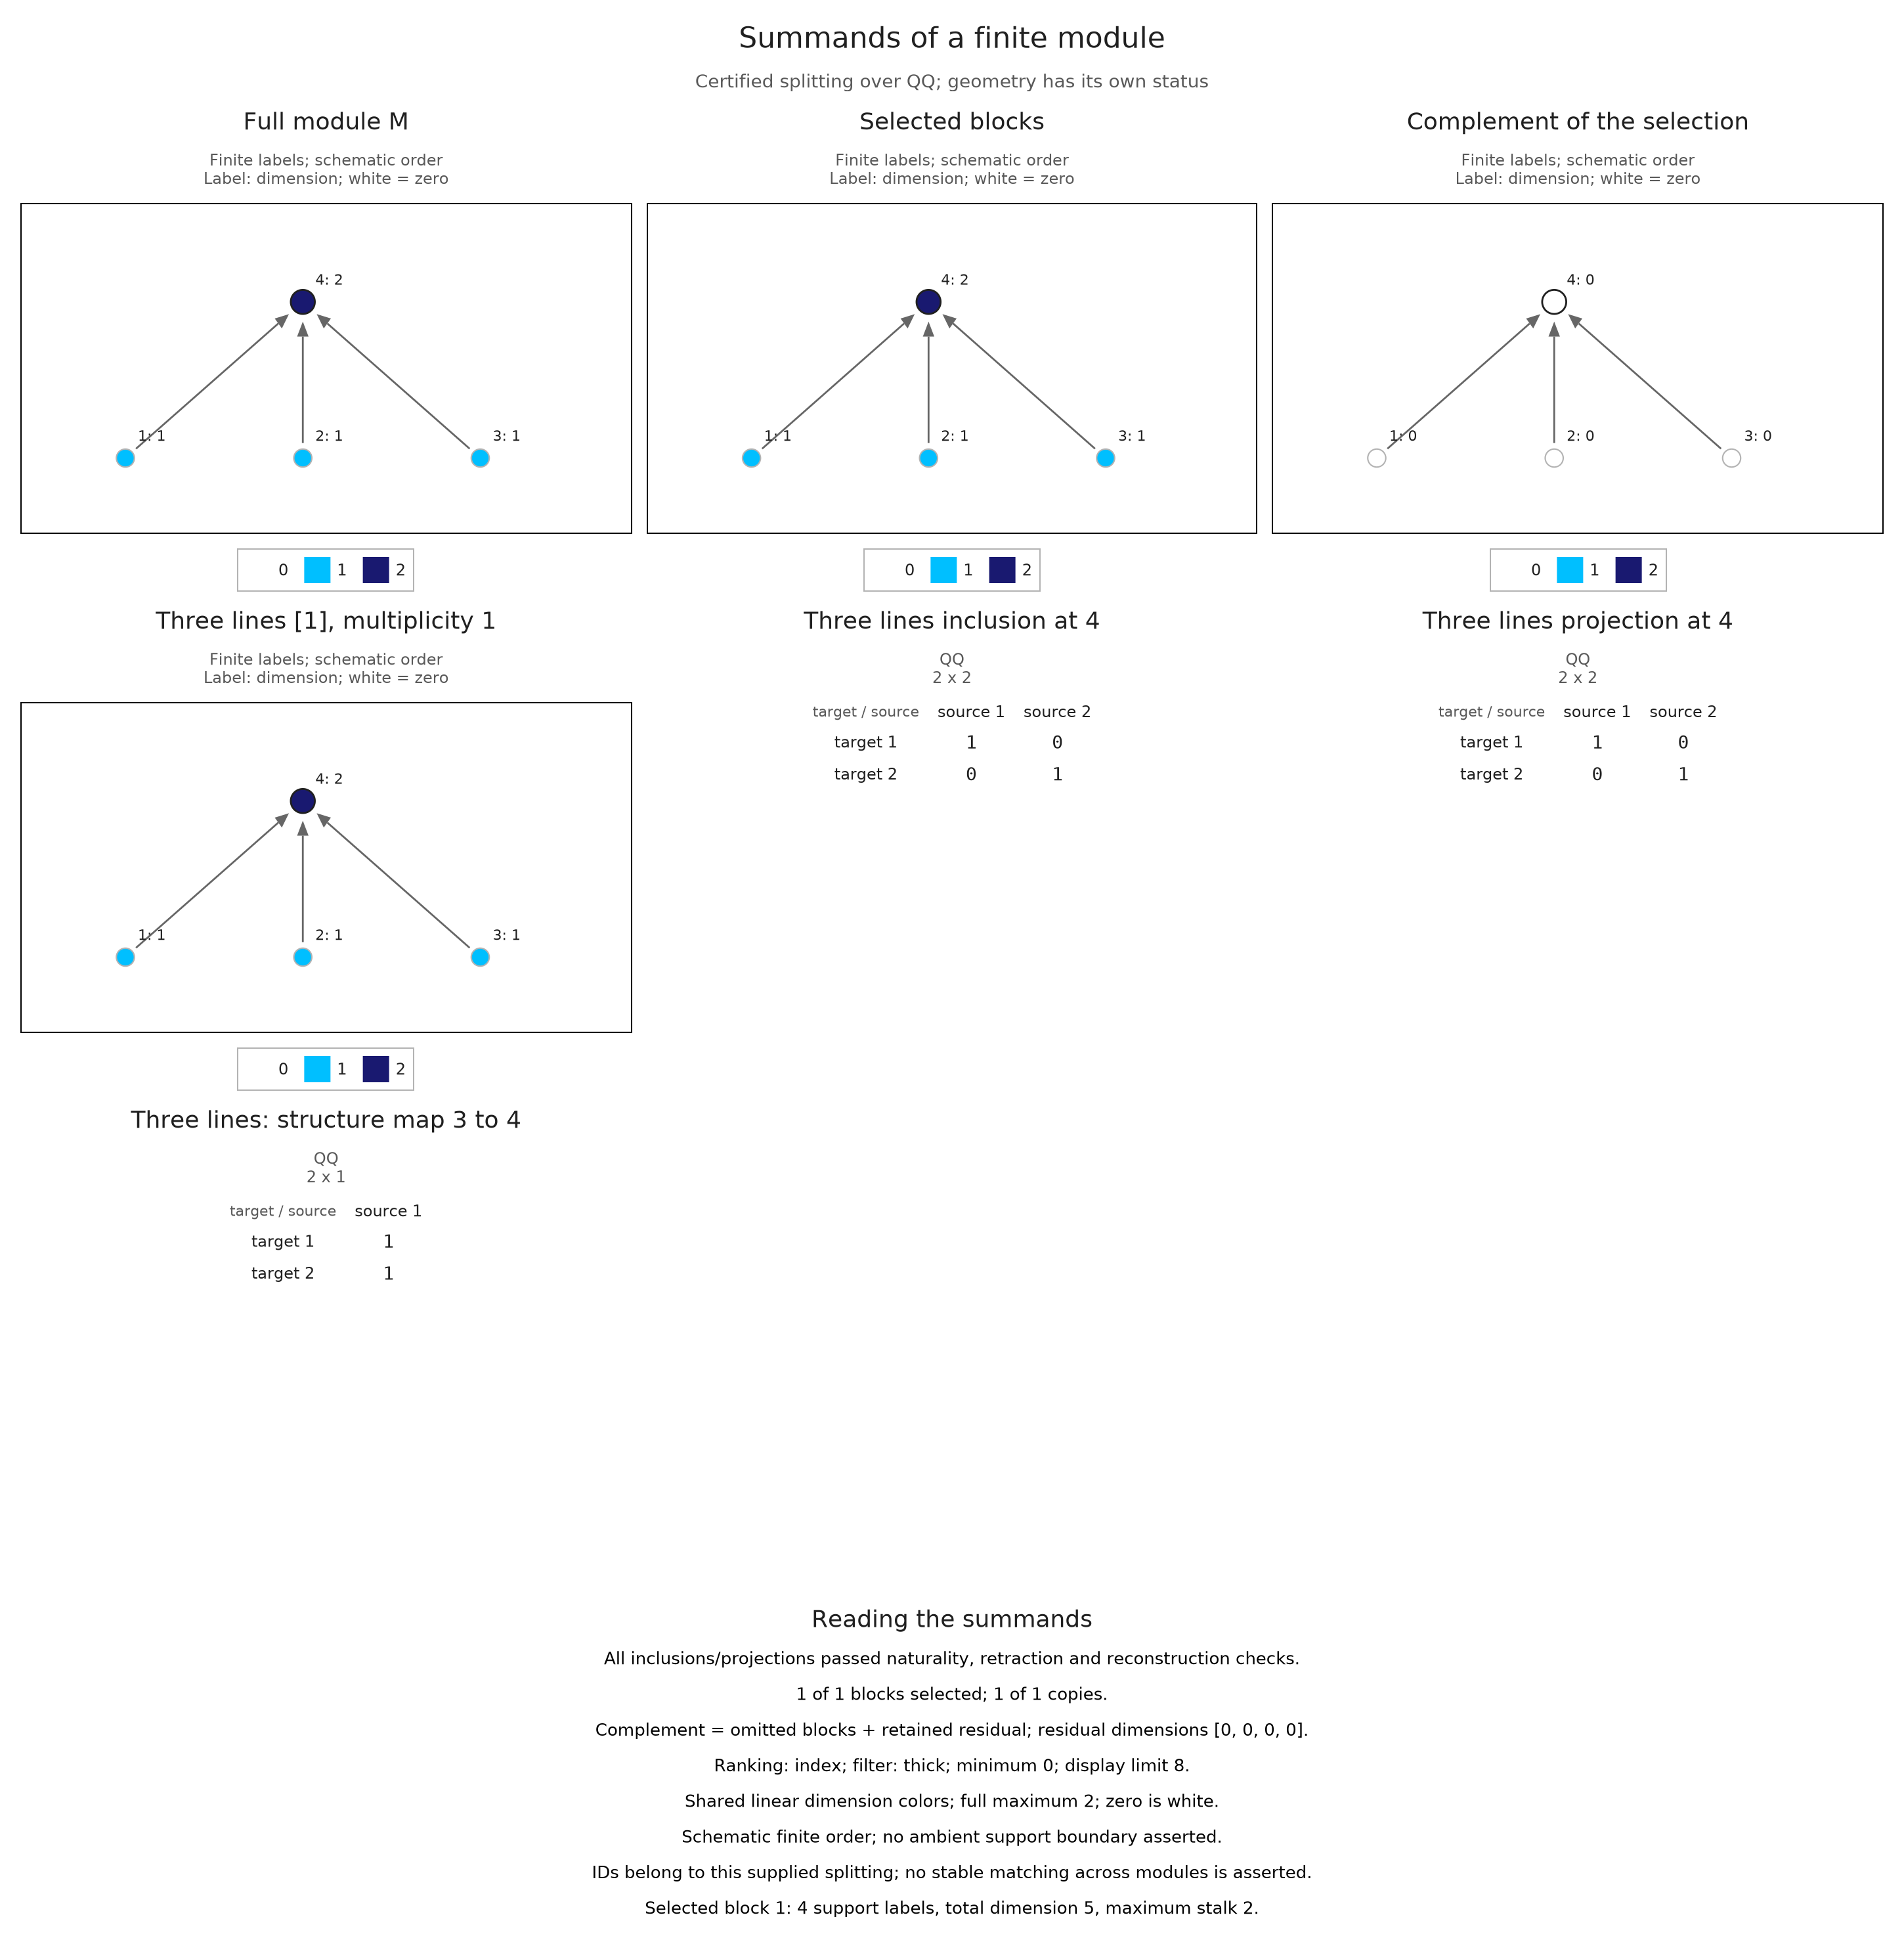

In [13]:
identity_map = OP.Modules.id_morphism(three_lines)
thick = OP.summand_collection(three_lines, [three_lines];
    inclusions=[identity_map], projections=[identity_map], labels=["Three lines"])
OP.visualize(thick; type_filter=:thick, pair=(3, 4), vertex=4)


The same retained data can be explored through `OP.visualize(viewer)` after importing WGLMakie. Previous/next buttons browse the displayed block IDs; the labelled fields also accept exact IDs, type filters, ranking choices and selected maps. Clicking a node or a classifier cell selects its finite label. The session keeps the last valid selection when an entry is invalid, and hover does not perform algebra. Live controls require a running Julia process; the saved figures on this page do not.

A supplied support approximation carries a different claim. `A.SummandSupportDrawing` accepts half-open box unions with a provenance and error statement, and its views retain the label “geometry unverified” alongside the checked splitting. It does not compute an approximation or infer a boundary from sample tracks. [Signed summaries](slices_diagrams.ipynb) and matched slice tracks have their own views because their coefficients and identities do not certify a module splitting.


## Bound a search deliberately

Candidate enumeration can grow exponentially. Use a chosen family when that is the intended question, and explicit budgets when attempting a complete search. An exhausted budget raises an error; it does not become a claim that a module fails to decompose. Exact rational and prime fields are supported. Numerical near-splittings over floating coefficients are a different problem.


In [14]:
budget = A.IntervalDecompositionBudget(max_vertices=4, max_dimension=16,
    max_matrix_entries=1000, max_antichains=16, max_candidates=256)
@assert OP.is_interval_decomposable(M; budget) === true
A.interval_candidates(M; budget)


3-element Vector{Vector{Int64}}:
 [1, 2, 3, 4]
 [2, 4]
 [4]

## Optional: change the view without changing the answer

The palette changes the categorical support colors; the dimension panels retain their fixed blue scale. Multiplicities, field and splitting equations remain the same.


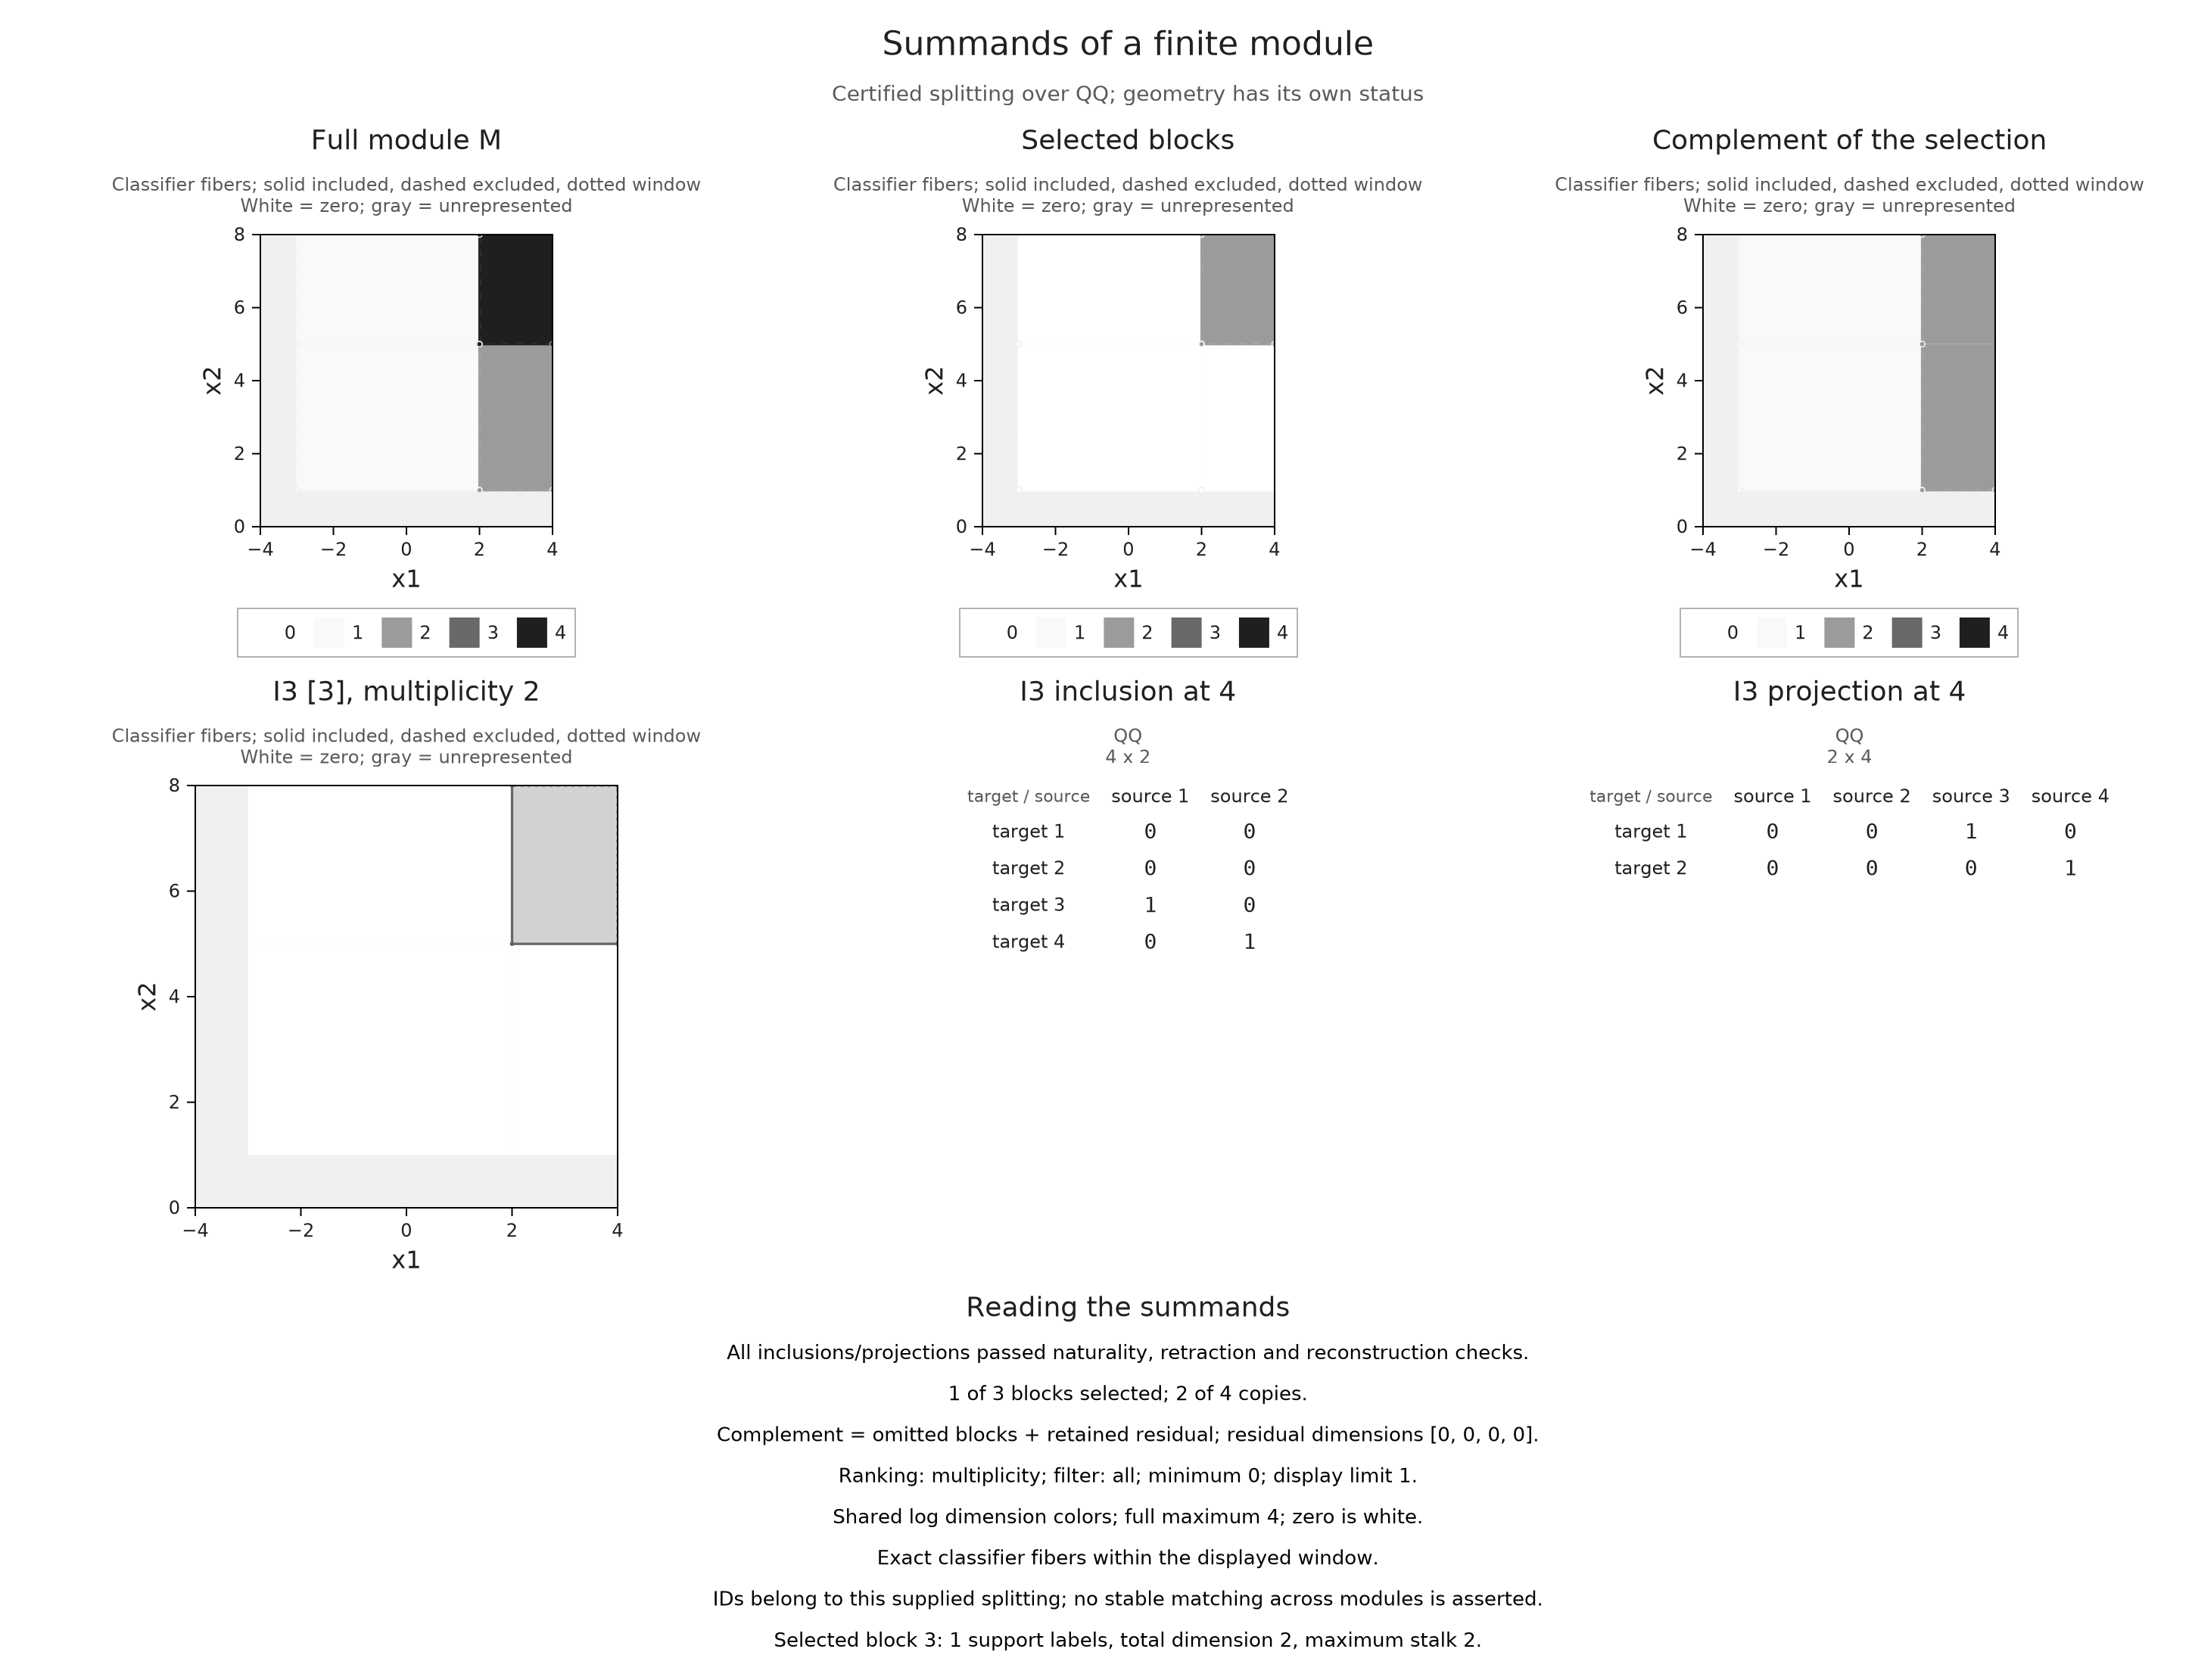

In [15]:
style = OP.VisualStyle(palette=:grayscale)
OP.visualize(A.inspection_snapshot(support_viewer); style)


## Continue with the algorithm

The [implementation account](../implementation/interval_decomposition.md) derives the composition pairing and the complete top/socle candidate search. For a different summary of the same finite object, [query generalized ranks](generalized_rank_queries.ipynb) and keep the restriction-versus-summand distinction visible.
